# Prognozowanie cen nieruchomości – Ames Housing

## 1. Wstępne przygotowanie i czyszczenie danych

### Cel projektu

Celem projektu jest stworzenie modelu uczenia maszynowego, który będzie przewidywał ceny sprzedaży nieruchomości na podstawie ich cech, takich jak powierzchnia, jakość wykonania czy rok budowy.

W projekcie wykorzystano zbiór danych Ames Housing, zawierający informacje o nieruchomościach sprzedanych w Ames w stanie Iowa (USA).

### Cel notebooka

Pierwszy etap projektu obejmuje wczytanie danych, sprawdzenie ich struktury, analizę brakujących wartości i duplikatów oraz wstępne czyszczenie zbioru.

Przygotowane dane zostaną wykorzystane w kolejnym notebooku do analizy zależności i budowania modeli prognozujących ceny nieruchomości.

### Import bibliotek

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\Admin\Documents\LearnIT\Projekt\ames-housing-price-prediction\data\AmesHousing.csv")

df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


### **Kontrola jakości danych**

Celem tego etapu jest sprawdzenie jakości zbioru Ames Housing przed przygotowaniem modeli uczenia maszynowego.

Analiza obejmuje:
- Sprawdzenie wymiarów zbioru danych i typów zmiennych.
- Identyfikację brakujących wartości (NaN).
- Wykrywanie zduplikowanych obserwacji.
- Analizę statystyk opisowych.
- Wstępną identyfikację wartości odstających.

Na podstawie wyników kontroli zostaną podjęte decyzje dotyczące czyszczenia i dalszego przetwarzania danych.

In [2]:
print("Liczba wierszy:", df.shape[0])
print("Liczba kolumn:", df.shape[1])

Liczba wierszy: 2930
Liczba kolumn: 82


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

In [4]:
braki = df.isnull().sum()

braki[braki > 0].sort_values(ascending=False)

Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Cond        159
Garage Yr Blt      159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
Bsmt Qual           80
BsmtFin Type 1      80
Mas Vnr Area        23
Bsmt Full Bath       2
Bsmt Half Bath       2
BsmtFin SF 1         1
BsmtFin SF 2         1
Electrical           1
Total Bsmt SF        1
Bsmt Unf SF          1
Garage Area          1
Garage Cars          1
dtype: int64

In [5]:
print("Liczba duplikatów:", df.duplicated().sum())

Liczba duplikatów: 0


In [6]:
df.describe()

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


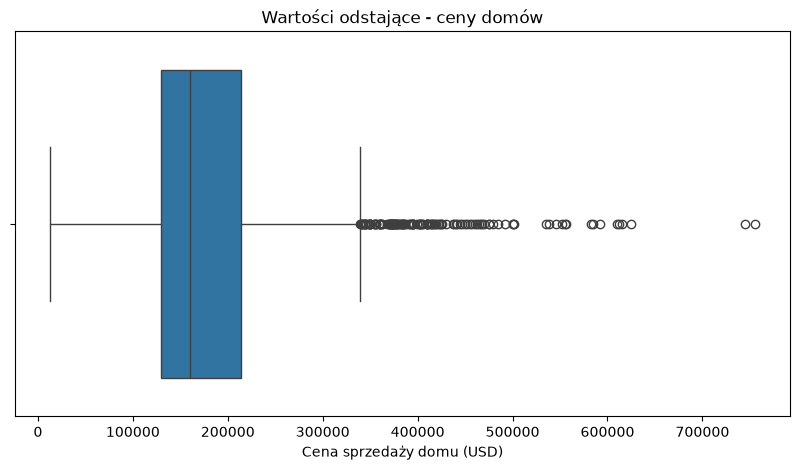

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(x=df["SalePrice"])

plt.title("Wartości odstające - ceny domów")
plt.xlabel("Cena sprzedaży domu (USD)")

plt.show()


In [8]:
df_clean = df.copy()


print("Liczba wierszy:", df_clean.shape[0])
print("Liczba kolumn:", df_clean.shape[1])

Liczba wierszy: 2930
Liczba kolumn: 82


In [9]:
kolumny_brak_wyposazenia = [
    "Pool QC",
    "Misc Feature",
    "Alley",
    "Fence",
    "Fireplace Qu"
]

for kolumna in kolumny_brak_wyposazenia:
    df_clean[kolumna] = df_clean[kolumna].fillna("None")

In [10]:
pozostale_braki = df_clean.isnull().sum()

pozostale_braki[pozostale_braki > 0].sort_values(
    ascending=False
)

Mas Vnr Type      1775
Lot Frontage       490
Garage Finish      159
Garage Yr Blt      159
Garage Qual        159
Garage Cond        159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Qual           80
BsmtFin Type 1      80
Bsmt Cond           80
Mas Vnr Area        23
Bsmt Full Bath       2
Bsmt Half Bath       2
Electrical           1
Bsmt Unf SF          1
BsmtFin SF 2         1
BsmtFin SF 1         1
Total Bsmt SF        1
Garage Area          1
Garage Cars          1
dtype: int64

In [11]:
print("Wiersze przed:", df.shape[0])
print("Wiersze po:", df_clean.shape[0])

print("Duplikaty:", df_clean.duplicated().sum())

print("Brakujące wartości przed:", df.isnull().sum().sum())
print("Brakujące wartości po:", df_clean.isnull().sum().sum())

Wiersze przed: 2930
Wiersze po: 2930
Duplikaty: 0
Brakujące wartości przed: 15749
Brakujące wartości po: 3496


### **Wnioski z wstępnej kontroli i czyszczenia danych**

Analizowany zbiór Ames Housing zawiera 2930 obserwacji i 82 kolumny opisujące nieruchomości.

Podczas kontroli jakości danych stwierdzono:

Brak całkowicie zduplikowanych wierszy.

Występowanie brakujących wartości w wielu kolumnach.

Szczególnie dużo braków w zmiennych dotyczących wyposażenia nieruchomości, takich jak basen, ogrodzenie czy kominek.

Obecność potencjalnych wartości odstających w cenach sprzedaży nieruchomości.

W pierwszym etapie czyszczenia uzupełniono wybrane braki oznaczające brak wyposażenia. Pozostałe braki wymagają dalszej analizy lub uzupełnienia na etapie preprocessingu.

Nie usunięto żadnych obserwacji ani wartości odstających bez dodatkowej weryfikacji.

In [12]:
df_clean[["Mas Vnr Type", "Mas Vnr Area"]].head(20)

,Mas Vnr Type,Mas Vnr Area
0,Stone,112.0
1,NaN,0.0
2,BrkFace,108.0
3,NaN,0.0
4,NaN,0.0
5,BrkFace,20.0
6,NaN,0.0
7,NaN,0.0
8,NaN,0.0
9,NaN,0.0


In [13]:
df_clean["Mas Vnr Type"].value_counts(dropna=False)

Mas Vnr Type
NaN        1775
BrkFace     880
Stone       249
BrkCmn       25
CBlock        1
Name: count, dtype: int64

In [14]:
df_clean.groupby(
    df_clean["Mas Vnr Type"].isnull()
)["Mas Vnr Area"].describe()

,count,mean,std,min,25%,50%,75%,max
Mas Vnr Type,,,,,,,,
False,1155.0,255.395671,203.297381,0.0,120.0,202.0,325.5,1600.0
True,1752.0,0.703196,14.711885,0.0,0.0,0.0,0.0,344.0


In [15]:
df_clean[
    (df_clean["Mas Vnr Type"].isnull()) &
    (df_clean["Mas Vnr Area"] > 0)
][["Mas Vnr Type", "Mas Vnr Area"]]

,Mas Vnr Type,Mas Vnr Area
363,NaN,344.0
403,NaN,312.0
441,NaN,285.0
1861,NaN,1.0
1913,NaN,1.0
2003,NaN,1.0
2528,NaN,288.0


In [16]:
df_clean.loc[
    (df_clean["Mas Vnr Type"].isnull()) &
    (df_clean["Mas Vnr Area"] == 0),
    "Mas Vnr Type"
] = "None"

In [17]:
df_clean["Mas Vnr Type"].value_counts(dropna=False)

Mas Vnr Type
None       1745
BrkFace     880
Stone       249
NaN          30
BrkCmn       25
CBlock        1
Name: count, dtype: int64

In [18]:
df_clean[
    df_clean["Mas Vnr Type"].isnull()
][["Mas Vnr Type", "Mas Vnr Area"]]

,Mas Vnr Type,Mas Vnr Area
55,NaN,NaN
363,NaN,344.0
403,NaN,312.0
441,NaN,285.0
484,NaN,NaN
517,NaN,NaN
538,NaN,NaN
867,NaN,NaN
1095,NaN,NaN
1119,NaN,NaN


### **Analiza brakujących wartości – Mas Vnr Type**

W kolumnie `Mas Vnr Type` wykryto 1775 brakujących wartości. W celu ich analizy porównano tę kolumnę z `Mas Vnr Area`, która określa powierzchnię okładziny elewacyjnej.

Analiza wykazała, że:
- W 1745 przypadkach powierzchnia okładziny wynosiła 0, dlatego brakujące wartości uzupełniono jako `None`, oznaczające brak okładziny.
- W 7 przypadkach powierzchnia była większa od 0, ale brakowało informacji o rodzaju okładziny.
- W 23 przypadkach brakowało zarówno rodzaju, jak i powierzchni okładziny.

Pozostałe 30 brakujących wartości pozostawiono bez zmian, ponieważ nie można jednoznacznie określić rodzaju okładziny. Zostaną one uwzględnione na etapie przygotowania danych do modelowania.

In [19]:
df_clean["Lot Frontage"].describe()

count    2440.000000
mean       69.224590
std        23.365335
min        21.000000
25%        58.000000
50%        68.000000
75%        80.000000
max       313.000000
Name: Lot Frontage, dtype: float64

In [20]:
df_clean["Lot Frontage"].isnull().sum()

np.int64(490)

### **Analiza brakujących wartości – Lot Frontage**

W kolumnie Lot Frontage brakuje 490 wartości, czyli około 16,7% danych.

Średnia wynosi około 69, a mediana 68. Wartości są do siebie zbliżone, jednak występują też znacznie większe wartości, np. maksymalna wynosi 313.

Na razie braki pozostawiono bez zmian. Zostaną uzupełnione na etapie przygotowania danych do modelowania, na podstawie danych treningowych.

In [21]:
kolumny_garaz = [
    "Garage Type",
    "Garage Finish",
    "Garage Qual",
    "Garage Cond",
    "Garage Yr Blt",
    "Garage Cars",
    "Garage Area"
]

df_clean[kolumny_garaz].isnull().sum()

Garage Type      157
Garage Finish    159
Garage Qual      159
Garage Cond      159
Garage Yr Blt    159
Garage Cars        1
Garage Area        1
dtype: int64

In [22]:
df_clean[
    df_clean["Garage Type"].isnull()
][["Garage Type", "Garage Cars", "Garage Area"]].head(20)

,Garage Type,Garage Cars,Garage Area
27,NaN,0.0,0.0
119,NaN,0.0,0.0
125,NaN,0.0,0.0
129,NaN,0.0,0.0
130,NaN,0.0,0.0
170,NaN,0.0,0.0
171,NaN,0.0,0.0
186,NaN,0.0,0.0
203,NaN,0.0,0.0
206,NaN,0.0,0.0


In [23]:
df_clean[
    df_clean["Garage Type"].notnull() &
    df_clean["Garage Finish"].isnull()
][kolumny_garaz]

,Garage Type,Garage Finish,Garage Qual,Garage Cond,Garage Yr Blt,Garage Cars,Garage Area
1356,Detchd,NaN,NaN,NaN,NaN,1.0,360.0
2236,Detchd,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
df_clean[
    df_clean["Garage Type"].isnull()
][["Garage Cars", "Garage Area"]].describe()

,Garage Cars,Garage Area
count,157.0,157.0
mean,0.0,0.0
std,0.0,0.0
min,0.0,0.0
25%,0.0,0.0
50%,0.0,0.0
75%,0.0,0.0
max,0.0,0.0


In [25]:
kolumny_garaz_kat = [
    "Garage Type",
    "Garage Finish",
    "Garage Qual",
    "Garage Cond"
]

for kolumna in kolumny_garaz_kat:
    df_clean.loc[
        df_clean["Garage Type"].isnull(),
        kolumna
    ] = "None"

In [26]:
df_clean[kolumny_garaz].isnull().sum()

Garage Type        0
Garage Finish    159
Garage Qual      159
Garage Cond      159
Garage Yr Blt    159
Garage Cars        1
Garage Area        1
dtype: int64

In [27]:
kolumny_garaz_kat = [
    "Garage Finish",
    "Garage Qual",
    "Garage Cond"
]

for kolumna in kolumny_garaz_kat:
    df_clean.loc[
        (df_clean["Garage Cars"] == 0) &
        (df_clean["Garage Area"] == 0),
        kolumna
    ] = "None"

In [28]:
df_clean[kolumny_garaz].isnull().sum()

Garage Type        0
Garage Finish      2
Garage Qual        2
Garage Cond        2
Garage Yr Blt    159
Garage Cars        1
Garage Area        1
dtype: int64

### **Analiza brakujących wartości – garaże**

W kolumnach dotyczących garaży występowało od 1 do 159 brakujących wartości.

Po sprawdzeniu danych okazało się, że 157 domów ma zerową powierzchnię garażu i 0 miejsc parkingowych. W tych przypadkach brakujące informacje o rodzaju, wykończeniu i stanie garażu uzupełniono wartością None.

Pozostałe braki pozostawiono do dalszego przygotowania danych, ponieważ dotyczą domów z niekompletnymi informacjami o garażu.

In [29]:
kolumny_piwnica = [
    "Bsmt Qual",
    "Bsmt Cond",
    "Bsmt Exposure",
    "BsmtFin Type 1",
    "BsmtFin Type 2",
    "Total Bsmt SF"
]

df_clean[kolumny_piwnica].isnull().sum()

Bsmt Qual         80
Bsmt Cond         80
Bsmt Exposure     83
BsmtFin Type 1    80
BsmtFin Type 2    81
Total Bsmt SF      1
dtype: int64

In [30]:
df_clean[
    df_clean["Bsmt Qual"].isnull()
][["Bsmt Qual", "Total Bsmt SF"]].head(20)

,Bsmt Qual,Total Bsmt SF
83,NaN,0.0
154,NaN,0.0
206,NaN,0.0
243,NaN,0.0
273,NaN,0.0
275,NaN,0.0
290,NaN,0.0
551,NaN,0.0
649,NaN,0.0
676,NaN,0.0


In [31]:
df_clean[
    df_clean["Bsmt Qual"].isnull()
]["Total Bsmt SF"].describe()

count    79.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: Total Bsmt SF, dtype: float64

In [32]:
df_clean[
    df_clean["Bsmt Qual"].isnull()
]["Total Bsmt SF"].isnull().sum()

np.int64(1)

In [33]:
kolumny_piwnica_kat = [
    "Bsmt Qual",
    "Bsmt Cond",
    "Bsmt Exposure",
    "BsmtFin Type 1",
    "BsmtFin Type 2"
]

for kolumna in kolumny_piwnica_kat:
    df_clean.loc[
        (df_clean["Total Bsmt SF"] == 0) &
        (df_clean[kolumna].isnull()),
        kolumna
    ] = "None"

In [34]:
df_clean[kolumny_piwnica].isnull().sum()

Bsmt Qual         1
Bsmt Cond         1
Bsmt Exposure     4
BsmtFin Type 1    1
BsmtFin Type 2    2
Total Bsmt SF     1
dtype: int64

In [35]:
df_clean[
    df_clean["Bsmt Exposure"].isnull()
][kolumny_piwnica]

,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin Type 2,Total Bsmt SF
66,Gd,TA,NaN,Unf,Unf,1595.0
1341,NaN,NaN,NaN,NaN,NaN,NaN
1796,Gd,TA,NaN,Unf,Unf,725.0
2779,Gd,TA,NaN,Unf,Unf,936.0


In [36]:
df_clean[
    df_clean["BsmtFin Type 2"].isnull()
][kolumny_piwnica]

,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin Type 2,Total Bsmt SF
444,Gd,TA,No,GLQ,NaN,3206.0
1341,NaN,NaN,NaN,NaN,NaN,NaN


### **Analiza brakujących wartości – piwnice**

W kolumnach dotyczących piwnic wykryto od 1 do 83 brakujących wartości.

Analiza wykazała, że:
- W 79 przypadkach brakowało informacji o jakości piwnicy, a jej powierzchnia wynosiła 0.
- W domach o zerowej powierzchni piwnicy brakujące informacje uzupełniono wartością `None`, oznaczającą brak piwnicy.
- Pozostałe braki dotyczą głównie domów, które mają piwnicę, ale nie wszystkie informacje o niej są dostępne.
- W jednym przypadku brakuje również informacji o powierzchni piwnicy.

Pozostałe brakujące wartości pozostawiono bez zmian. Zostaną one uwzględnione podczas przygotowania danych do modelowania.

In [37]:
braki = df_clean.isnull().sum()

braki[braki > 0].sort_values(ascending=False)

Lot Frontage      490
Garage Yr Blt     159
Mas Vnr Type       30
Mas Vnr Area       23
Bsmt Exposure       4
Garage Finish       2
Bsmt Half Bath      2
Garage Qual         2
BsmtFin Type 2      2
Bsmt Full Bath      2
Garage Cond         2
Bsmt Cond           1
Bsmt Qual           1
Electrical          1
Total Bsmt SF       1
Bsmt Unf SF         1
BsmtFin SF 2        1
BsmtFin SF 1        1
BsmtFin Type 1      1
Garage Area         1
Garage Cars         1
dtype: int64

In [38]:
print("Liczba brakujących wartości:", df_clean.isnull().sum().sum())

print("Liczba wierszy:", df_clean.shape[0])

print("Liczba kolumn:", df_clean.shape[1])

Liczba brakujących wartości: 728
Liczba wierszy: 2930
Liczba kolumn: 82


In [39]:
print("Liczba wierszy:", df_clean.shape[0])
print("Liczba kolumn:", df_clean.shape[1])
print("Duplikaty:", df_clean.duplicated().sum())
print("Pozostałe braki:", df_clean.isnull().sum().sum())
print("Braki w SalePrice:", df_clean["SalePrice"].isnull().sum())

Liczba wierszy: 2930
Liczba kolumn: 82
Duplikaty: 0
Pozostałe braki: 728
Braki w SalePrice: 0


### **Podsumowanie czyszczenia danych**

Po wstępnym czyszczeniu zbiór nadal zawiera 2930 wierszy i 82 kolumny. Nie usunięto żadnych nieruchomości. W zbiorze nie wykryto również zduplikowanych wierszy.

Podczas czyszczenia danych:
- Uzupełniono część brakujących wartości oznaczających brak określonych elementów domu, takich jak garaż, piwnica czy okładzina elewacyjna.
- Zachowano wszystkie nieruchomości znajdujące się w zbiorze.
- Pozostawiono braki, których nie można było jednoznacznie uzupełnić.

Po czyszczeniu pozostało **728 brakujących wartości**, głównie w kolumnach `Lot Frontage` i `Garage Yr Blt`.

Pozostałe braki zostaną uwzględnione podczas przygotowania danych do modelowania, po podziale na zbiór treningowy i testowy.

Dane są gotowe do dalszej analizy i budowania modeli prognozujących ceny nieruchomości.

In [40]:
df_clean.to_csv(
    r"C:\Users\Admin\Documents\LearnIT\Projekt\ames-housing-price-prediction\data\ames_cleaned.csv",
    index=False
)
print("Pozostałe braki:", df_clean.isnull().sum().sum())
print("Zapisano oczyszczone dane.")

Pozostałe braki: 728
Zapisano oczyszczone dane.
